In [2]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

import os
from PIL import Image

# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [11]:
from pathlib import Path

cwd = Path.cwd()
print("Current working directory:", cwd)

if (cwd / "data").exists() and (cwd / "notebooks").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").exists() and (cwd.name == "notebooks" or (cwd.parent / "notebooks").exists()):
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"
DATA_DIR = PROJECT_ROOT / "data" / "processed"
TEST_DIR = DATA_DIR / "test"
MODEL_PATH = NOTEBOOKS_DIR / "best_balanced_efficientnet_b0.pth"

class_names = ['real', 'deepfake', 'edited', 'ai_generated']
num_classes = len(class_names)

print("Project root:", PROJECT_ROOT)
print("Test dir:", TEST_DIR)
print("Model path:", MODEL_PATH)
print("Model exists:", MODEL_PATH.exists())

Current working directory: c:\Extra stuff\capstone\DeepfakeProject\DeepfakeProject\notebooks
Project root: c:\Extra stuff\capstone\DeepfakeProject\DeepfakeProject
Test dir: c:\Extra stuff\capstone\DeepfakeProject\DeepfakeProject\data\processed\test
Model path: c:\Extra stuff\capstone\DeepfakeProject\DeepfakeProject\notebooks\best_balanced_efficientnet_b0.pth
Model exists: True


In [12]:
model = models.efficientnet_b0(weights=None)

model.classifier = nn.Sequential(
    nn.Dropout(0.2),
    nn.Linear(model.classifier[1].in_features, num_classes)
)

checkpoint = torch.load(MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint)

model = model.to(device)
model.eval()

print("Model loaded successfully.")

C:\Users\surya\AppData\Local\Temp\ipykernel_31912\2269662815.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(MODEL_PATH, map_location=device)


Model loaded successfully.


In [46]:
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transform)

print("Number of test images:", len(test_dataset))
print("Dataset classes:", test_dataset.classes)
print("Class to index mapping:", test_dataset.class_to_idx)

# IMPORTANT FIX
class_names = test_dataset.classes
print("Final class names used:", class_names)

Number of test images: 3165
Dataset classes: ['ai_generated', 'deepfake', 'edited', 'real']
Class to index mapping: {'ai_generated': 0, 'deepfake': 1, 'edited': 2, 'real': 3}
Final class names used: ['ai_generated', 'deepfake', 'edited', 'real']


In [47]:
from torch.utils.data import DataLoader

batch_size = 32

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Test dataloader created successfully.")
print("Number of test batches:", len(test_loader))

Test dataloader created successfully.
Number of test batches: 99


In [48]:
images, labels = next(iter(test_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Sample labels:", labels[:10].tolist())

Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])
Sample labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [49]:
from collections import Counter

label_counter = Counter()

for _, labels in test_loader:
    label_counter.update(labels.tolist())

print("Label distribution from dataloader:")
for idx, count in sorted(label_counter.items()):
    print(f"{idx} ({class_names[idx]}): {count}")

Label distribution from dataloader:
0 (ai_generated): 24
1 (deepfake): 1580
2 (edited): 38
3 (real): 1523


In [50]:
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

print("Prediction completed.")
print("Total predictions:", len(all_preds))

Prediction completed.
Total predictions: 3165


In [51]:
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

print("Predictions shape:", all_preds.shape)
print("Labels shape:", all_labels.shape)
print("Probabilities shape:", all_probs.shape)

Predictions shape: (3165,)
Labels shape: (3165,)
Probabilities shape: (3165, 4)


In [52]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(all_labels, all_preds)
print(f"Test Accuracy: {accuracy:.4f}\n")

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    digits=4
)

print("Classification Report:\n")
print(report)

Test Accuracy: 0.9630

Classification Report:

              precision    recall  f1-score   support

ai_generated     0.8750    0.8750    0.8750        24
    deepfake     0.9676    0.9639    0.9658      1580
      edited     0.8537    0.9211    0.8861        38
        real     0.9626    0.9645    0.9636      1523

    accuracy                         0.9630      3165
   macro avg     0.9147    0.9311    0.9226      3165
weighted avg     0.9631    0.9630    0.9631      3165



In [53]:
import pandas as pd

cm = confusion_matrix(all_labels, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {cls}" for cls in class_names],
    columns=[f"Pred: {cls}" for cls in class_names]
)

# Force full display
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("\nConfusion Matrix:\n")
display(cm_df)


Confusion Matrix:



,Pred: ai_generated,Pred: deepfake,Pred: edited,Pred: real
Actual: ai_generated,21,0,3,0
Actual: deepfake,0,1523,0,57
Actual: edited,3,0,35,0
Actual: real,0,51,3,1469


Model Clashes:
deepfake ↔ real & 
edited ↔ ai_generated

Human reasoning according to me
deepfake vs real → subtle differences & 
edited vs ai_generated → both are synthetic/manipulated

In [54]:
misclassified = []

for i, (true_label, pred_label) in enumerate(zip(all_labels, all_preds)):
    if true_label != pred_label:
        img_path, _ = test_dataset.samples[i]
        confidence = float(all_probs[i][pred_label])

        misclassified.append({
            "index": i,
            "img_path": img_path,
            "true_label": class_names[true_label],
            "pred_label": class_names[pred_label],
            "confidence": confidence
        })

print("Total misclassified samples:", len(misclassified))

Total misclassified samples: 117


In [55]:
import pandas as pd
misclassified_df = pd.DataFrame(misclassified)
display(misclassified_df.head(10))

,index,img_path,true_label,pred_label,confidence
0,11,c:\Extra stuff\capstone\DeepfakeProject\Deepfa...,ai_generated,edited,0.967691
1,15,c:\Extra stuff\capstone\DeepfakeProject\Deepfa...,ai_generated,edited,0.865284
2,23,c:\Extra stuff\capstone\DeepfakeProject\Deepfa...,ai_generated,edited,0.699065
3,52,c:\Extra stuff\capstone\DeepfakeProject\Deepfa...,deepfake,real,0.751947
4,89,c:\Extra stuff\capstone\DeepfakeProject\Deepfa...,deepfake,real,0.784296
5,114,c:\Extra stuff\capstone\DeepfakeProject\Deepfa...,deepfake,real,0.952399
6,237,c:\Extra stuff\capstone\DeepfakeProject\Deepfa...,deepfake,real,0.499280
7,239,c:\Extra stuff\capstone\DeepfakeProject\Deepfa...,deepfake,real,0.502662
8,337,c:\Extra stuff\capstone\DeepfakeProject\Deepfa...,deepfake,real,0.998418
9,395,c:\Extra stuff\capstone\DeepfakeProject\Deepfa...,deepfake,real,0.998659


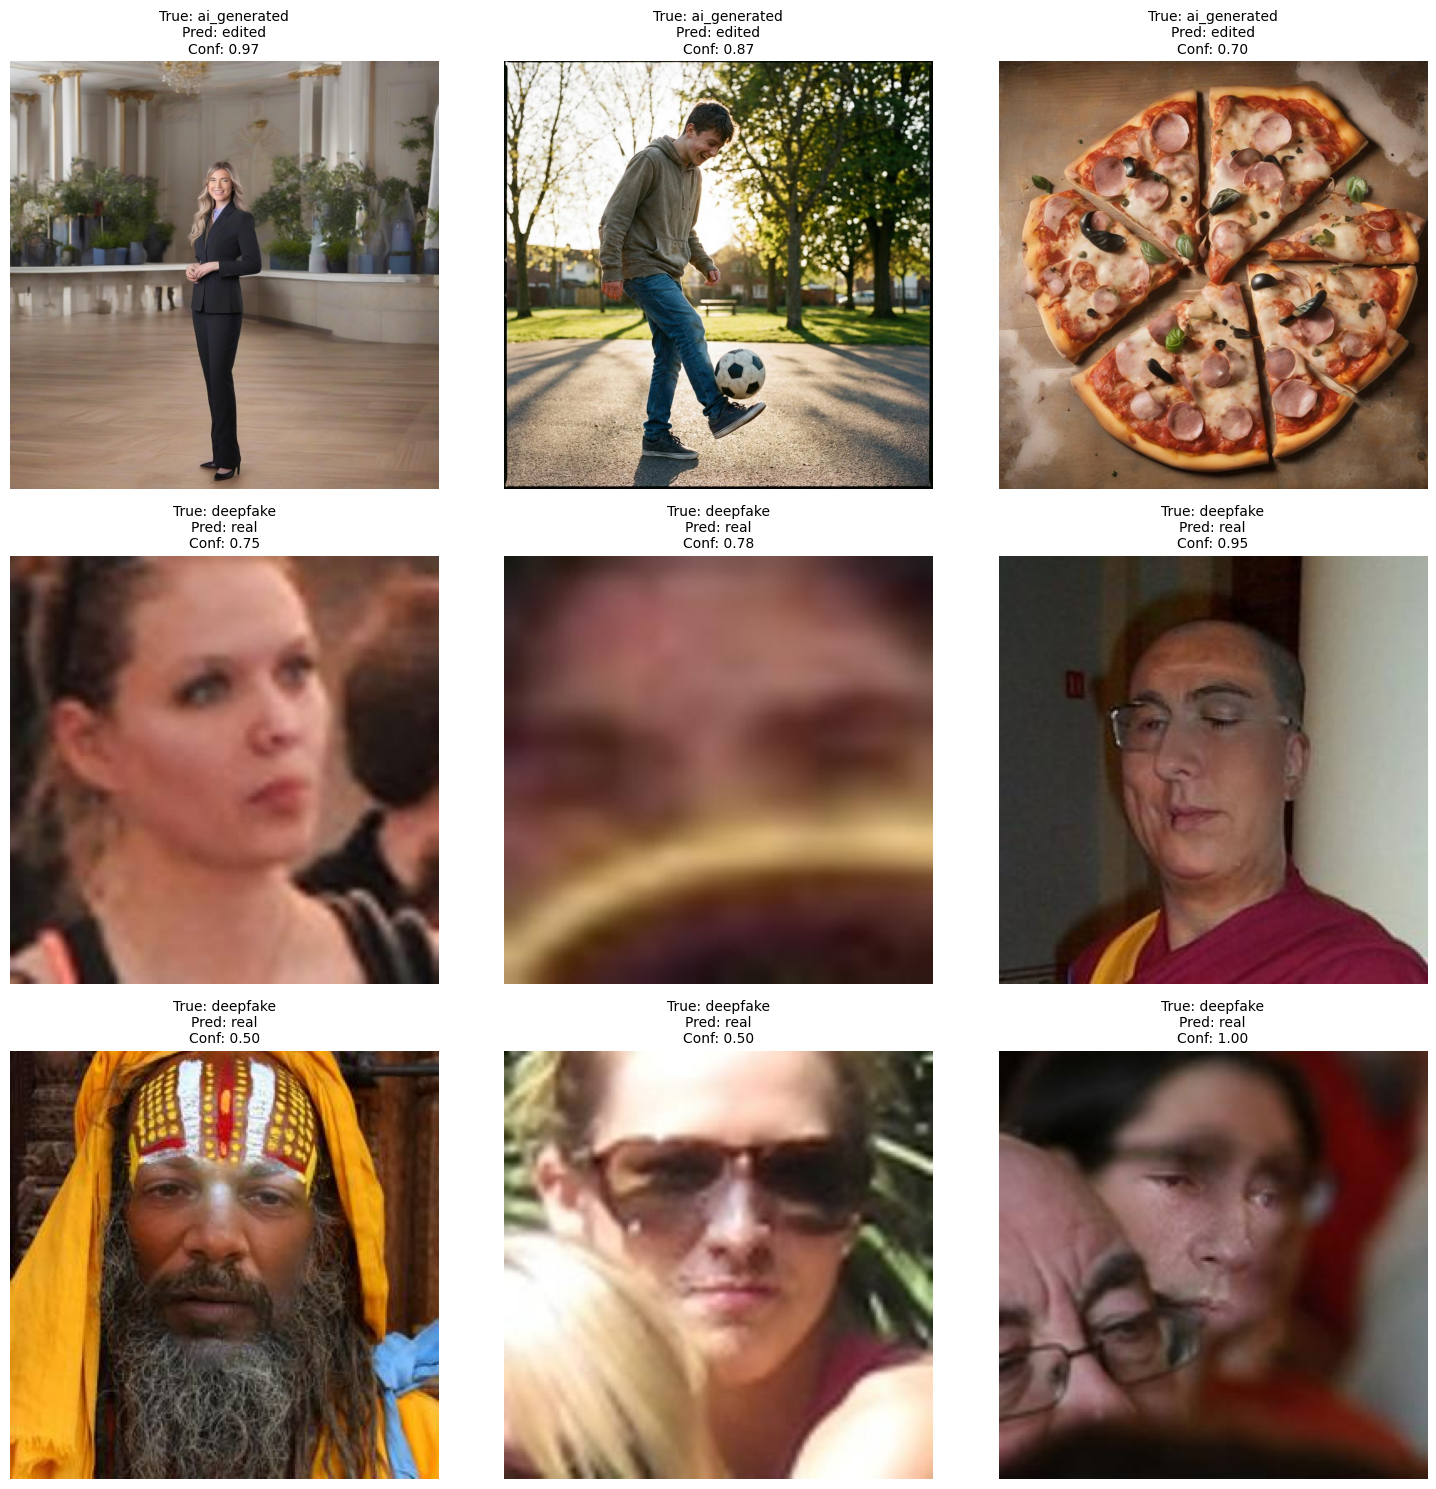

In [56]:
num_samples = min(9, len(misclassified))
plt.figure(figsize=(15, 15))

for i in range(num_samples):
    sample = misclassified[i]
    img = Image.open(sample["img_path"]).convert("RGB")

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(
        f"True: {sample['true_label']}\nPred: {sample['pred_label']}\nConf: {sample['confidence']:.2f}",
        fontsize=10
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [57]:
from collections import Counter

error_pairs = Counter()

for true, pred in zip(all_labels, all_preds):
    if true != pred:
        pair = (class_names[true], class_names[pred])
        error_pairs[pair] += 1

print("Top misclassification pairs:\n")

for pair, count in error_pairs.most_common():
    print(f"{pair[0]} → {pair[1]}: {count}")

Top misclassification pairs:

deepfake → real: 57
real → deepfake: 51
ai_generated → edited: 3
edited → ai_generated: 3
real → edited: 3
